# F02_04 — ARIMA: dependencia y selección
## Propósito y conexión con Semana 3
ETS actualiza nivel y tendencia. Ahora modelamos dependencia entre valores y entre innovaciones, estabilizando la serie cuando sea necesario. Al terminar podrá explicar estacionariedad, diferencias, AR, MA y ARIMA, evaluar AutoARIMA críticamente y decidir si aporta valor frente a referencias simples.

Trabaje en la secuencia 📘 Concepto → 🌍 Contexto → 💻 Entendamos el código → 🧠 Predice → ▶ Ejecuta → 🔎 Interpreta → ▶ Ver respuesta razonada → 🛠️ Modifica. Hay menos ayuda de sintaxis: formule predicciones y justifique sus cambios.

Autocontenido, sin descargas ni notebooks previos. Lectura: [FPP3, capítulo 9](https://otexts.com/fpp3/arima.html): estacionariedad (§9.1), AR (§9.3), MA (§9.4), ARIMA (§9.5), estimación y selección, y ARIMA vs ETS (§9.10). En la web consultada, estimación aparece en §9.6 y el procedimiento automático en §9.7; ambos apoyan esta sesión. SARIMA no es requisito.

## 1. 🌍 Contexto y preparación
`austa.csv`: 36 observaciones anuales (1980–2015) de visitantes internacionales a Australia, en millones. Permite estudiar crecimiento sin componente estacional y difiere del uso de Internet de Semana 3. Reservamos las últimas 6: $h=6$ años. Train tiene solo 30 observaciones: ACF/PACF y órdenes altos tienen mucha incertidumbre.

### 💻 Entendamos el código
La búsqueda admite `content/data/fpppy/` y `data/fpppy/`, recorriendo la carpeta actual y sus ancestros. Renombramos el esquema local `Year`, `Visitors`.

### 🧠 Predice
¿Por qué una serie creciente puede mostrar ACF persistente sin necesitar muchos términos AR?

### ▶ Ejecuta

Train: 1980 2009 30
Test: 2010 2015 6


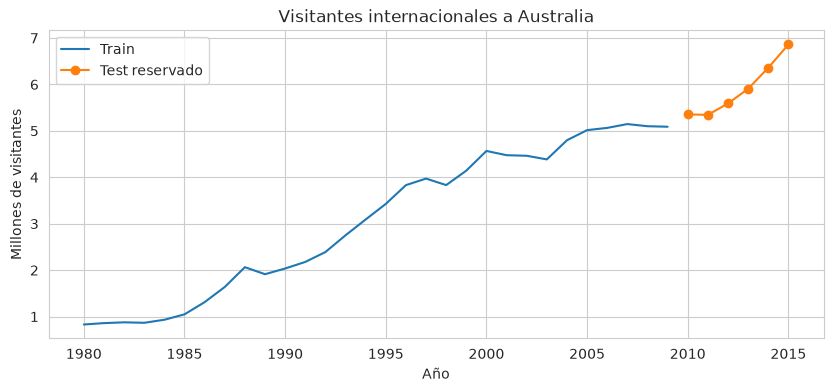

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf
from statsforecast.models import ARIMA, AutoARIMA, AutoETS
from IPython.display import display
candidatos = [base/ruta for base in [Path.cwd(), *Path.cwd().parents]
              for ruta in ['data/fpppy','content/data/fpppy']]
DATA_DIR = next((p for p in candidatos if (p/'austa.csv').is_file()),None)
assert DATA_DIR is not None, 'Busque austa.csv en data/fpppy o content/data/fpppy'
sns.set_style('whitegrid')
serie = (pd.read_csv(DATA_DIR/'austa.csv').rename(columns={'Year':'anio','Visitors':'y'})
         .sort_values('anio').reset_index(drop=True))
assert serie.anio.is_unique and np.all(np.diff(serie.anio)==1)
assert np.isfinite(serie.y).all()
h = 6
train,test = serie.iloc[:-h].copy(),serie.iloc[-h:].copy()
y_train,y_test = train.y.to_numpy(dtype=float),test.y.to_numpy(dtype=float)
assert train.anio.max()<test.anio.min()
print('Train:',train.anio.min(),train.anio.max(),len(train))
print('Test:',test.anio.min(),test.anio.max(),len(test))
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(train.anio,y_train,label='Train')
ax.plot(test.anio,y_test,'o-',label='Test reservado')
ax.set(title='Visitantes internacionales a Australia',xlabel='Año',ylabel='Millones de visitantes')
ax.legend()
plt.show()

## 2. 📘 Concepto: dependencia y estacionariedad
Una serie aproximadamente estacionaria mantiene media, varianza y dependencia entre observaciones separadas por el mismo rezago aproximadamente estables en el tiempo. No significa que sea constante ni que carezca de autocorrelación. La tendencia puede producir autocorrelaciones persistentes porque períodos cercanos comparten un nivel cambiante.

### ▶ Ejecuta

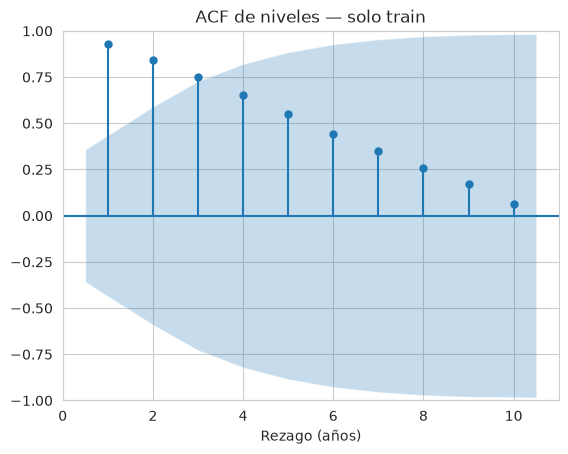

In [12]:
plot_acf(y_train,lags=10,zero=False)
plt.title('ACF de niveles — solo train')
plt.xlabel('Rezago (años)')
plt.show()

### 🔎 Interpreta
¿El nivel parece estable? ¿La ACF alta demuestra un AR de orden alto? Examine también variabilidad.

<details>
<summary><strong>▶ Ver respuesta razonada</strong></summary>

El nivel cambia. La ACF mezcla persistencia y tendencia; no prueba un AR de orden alto. Estacionariedad permite dependencia si su estructura es estable. La muestra corta limita la evidencia.

</details>

## 3. 📘 Concepto: primera diferencia
$$
\Delta y_t=y_t-y_{t-1}
$$
Mide cambio anual en millones, pierde una observación y no es un porcentaje. Si estabiliza el nivel, podemos modelar los cambios. **Diferenciar demasiado puede introducir autocorrelación negativa artificial, aumentar variabilidad y complicar el modelo.** Una tendencia determinista también admite otros tratamientos; verla no demuestra una raíz unitaria.

Priorizamos gráficos y estructura; no necesitamos una batería de pruebas ni un p-valor como criterio único.

### 🧠 Predice
¿La media de las diferencias debe ser cero para que sean estacionarias?

### ▶ Ejecuta

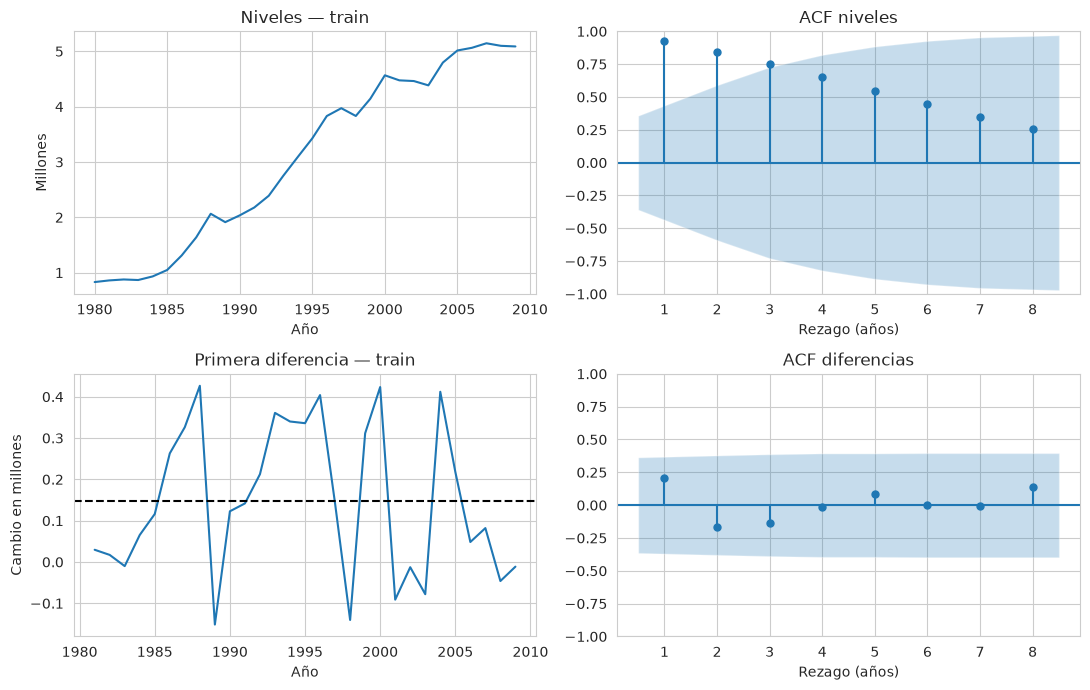

Media de cambios: 0.14683695586206896 Desviación: 0.18281921147887945


In [13]:
dy=np.diff(y_train)
fig,axes=plt.subplots(2,2,figsize=(11,7))
axes[0,0].plot(train.anio,y_train)
axes[0,0].set(title='Niveles — train',xlabel='Año',ylabel='Millones')
axes[1,0].plot(train.anio.iloc[1:],dy)
axes[1,0].axhline(dy.mean(),color='black',linestyle='--')
axes[1,0].set(title='Primera diferencia — train',xlabel='Año',ylabel='Cambio en millones')
plot_acf(y_train,lags=8,zero=False,ax=axes[0,1])
plot_acf(dy,lags=8,zero=False,ax=axes[1,1])
axes[0,1].set(title='ACF niveles',xlabel='Rezago (años)')
axes[1,1].set(title='ACF diferencias',xlabel='Rezago (años)')
plt.tight_layout()
plt.show()
print('Media de cambios:',dy.mean(),'Desviación:',dy.std(ddof=1))

### 🔎 Interpreta
Justifique provisionalmente $d=1$ usando train y compare dependencia y nivel.

<details>
<summary><strong>▶ Ver respuesta razonada</strong></summary>

Una media positiva de cambios es compatible con estacionariedad alrededor de una constante. La diferencia reduce la tendencia y la persistencia de ACF. Esto apoya provisionalmente d=1, sin demostrar estacionariedad ni imponerlo a todas las series.

</details>

### 🛠️ Modifica
Grafique `np.diff(dy)` y su ACF. Compare varianza y lag 1 y explique por qué otra diferencia necesita evidencia. Conserve d=1 en la comparación principal.

## 4. 📘 Concepto: AR(1), memoria de valores
Para una serie estacionaria $Z_t$ con media $\mu$:
$$
Z_t-\mu=\phi_1(Z_{t-1}-\mu)+\varepsilon_t,\qquad |\phi_1|<1
$$
La innovación $\varepsilon_t$ tiene media cero, varianza estable y es impredecible a partir del pasado. $\phi_1$ mide persistencia, no probabilidad: cerca de 1, un desvío tarda en disiparse; negativo, tiende a alternar. Con $\phi_1=1$ salimos del AR(1) estacionario y conectamos con random walk.

## 5. 📘 Concepto: MA(1), memoria de innovaciones
$$
Z_t=\mu+\varepsilon_t+\theta_1\varepsilon_{t-1}
$$
Un shock influye en el período actual y siguiente. **MA no es el promedio móvil para suavizar una gráfica.** Las innovaciones no se observan directamente: se estiman al ajustar. Usamos convención de signo positivo; otras fuentes pueden cambiar el signo de theta.

### 🌍 Contexto
Simulamos mecanismos conocidos para separar memoria de valores y de shocks; no ajustamos estas simulaciones a visitantes.

### 🧠 Predice
¿Qué ocurre al pasar phi de 0.7 a 0.95? ¿Cuántos períodos reciben directamente un shock de MA(1)?

### ▶ Ejecuta

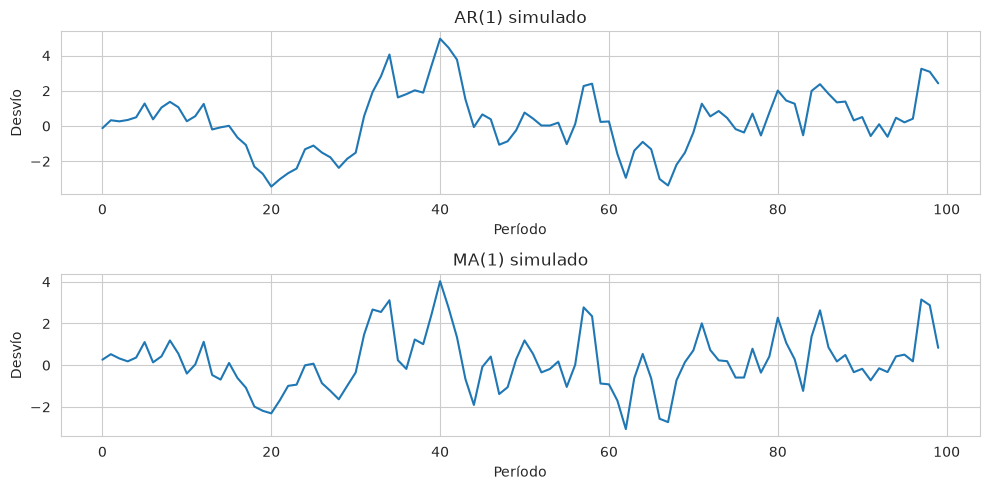

In [14]:
rng=np.random.default_rng(2026)
eps=rng.normal(size=700)
z_ar=np.zeros(700)
for t in range(1,len(eps)):
    z_ar[t]=0.7*z_ar[t-1]+eps[t]
z_ma=eps[1:]+0.7*eps[:-1]
z_ar,z_ma=z_ar[200:],z_ma[199:]
fig,axes=plt.subplots(2,1,figsize=(10,5))
for ax,z,nombre in zip(axes,[z_ar,z_ma],['AR(1)','MA(1)']):
    ax.plot(z[:100])
    ax.set(title=nombre+' simulado',xlabel='Período',ylabel='Desvío')
plt.tight_layout()
plt.show()

<details>
<summary><strong>▶ Ver respuesta razonada</strong></summary>

Con phi=0.95 aumenta la persistencia: el shock se propaga recursivamente con potencias de phi. En MA(1) el efecto directo termina después del período siguiente; su dependencia surge de innovaciones compartidas.

</details>

## 6. 📘 Concepto: ACF y PACF
ACF mide asociación total con cada rezago. PACF resume asociación lineal con ese rezago controlando los intermedios.

| Modelo puro estacionario | ACF poblacional | PACF poblacional |
|---|---|---|
| AR(p) | Tiende a decaer | Corta después de p |
| MA(q) | Corta después de q | Tiende a decaer |
| ARMA | Suele decaer | Suele decaer |

**Guía heurística, no regla infalible de selección.** Las estimaciones fluctúan; en datos reales rara vez hay patrones perfectos. Las bandas son aproximadas y mirar muchos rezagos produce picos por azar. Examine la serie que va a modelar después de decidir diferenciación.

### 💻 Entendamos el código
`method='ywm'` fija estimador PACF; `zero=False` omite lag cero. Usamos 8 rezagos por las 29 diferencias reales.

### ▶ Ejecuta

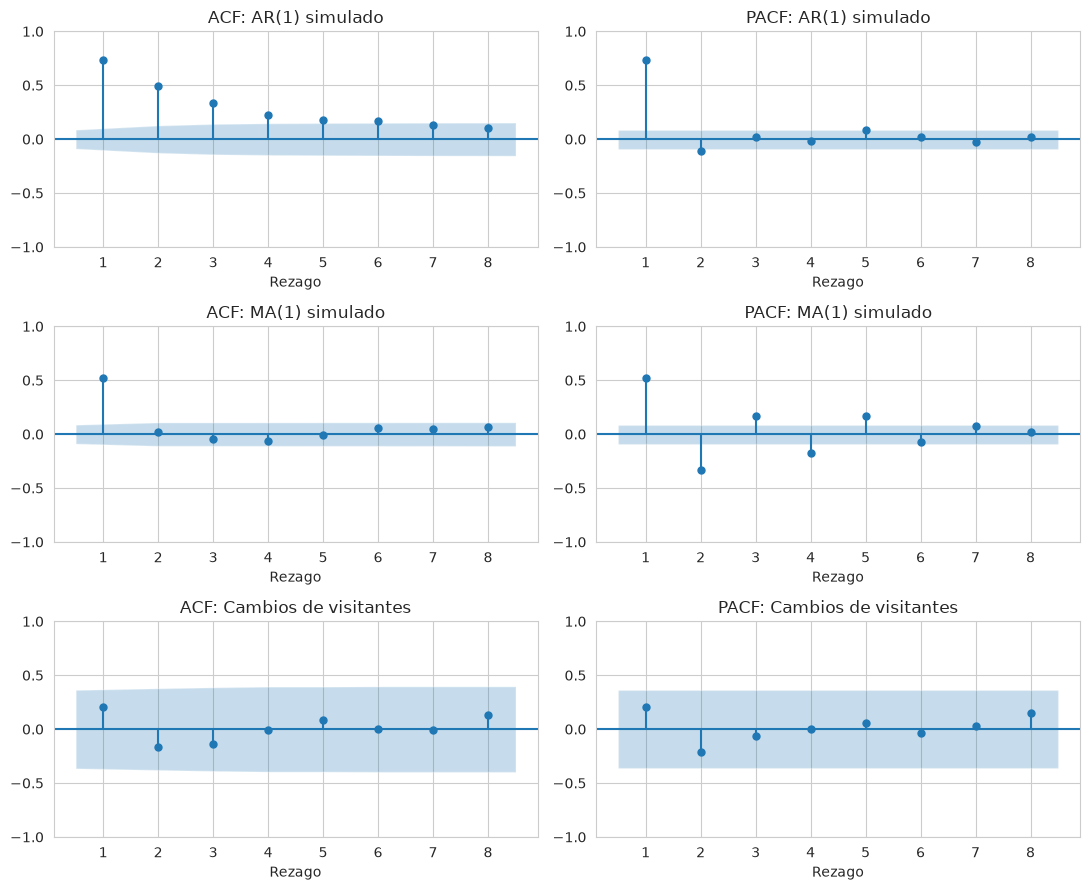

In [15]:
fig,axes=plt.subplots(3,2,figsize=(11,9))
for fila,z,nombre in zip(axes,[z_ar,z_ma,dy],['AR(1) simulado','MA(1) simulado','Cambios de visitantes']):
    plot_acf(z,lags=8,zero=False,ax=fila[0])
    plot_pacf(z,lags=8,zero=False,method='ywm',ax=fila[1])
    fila[0].set(title='ACF: '+nombre,xlabel='Rezago')
    fila[1].set(title='PACF: '+nombre,xlabel='Rezago')
plt.tight_layout()
plt.show()

### 🔎 Interpreta
Distinga patrón ideal y estimación. ¿La serie real obliga a un AR(1)?

<details>
<summary><strong>▶ Ver respuesta razonada</strong></summary>

Las simulaciones permiten reconocer patrones aproximados. En visitantes, un pico aislado no obliga a agregar términos. Un AR(1) en diferencias será una hipótesis parsimoniosa a contrastar; podría bastar un modelo más simple.

</details>

### 🛠️ Modifica
Cambie el signo de theta en MA y explique el cambio de ACF(1). Restaure la simulación.

## 7. 📘 Concepto: ARIMA(p,d,q)
Aplicamos d diferencias a $Y_t$ y modelamos el resultado como ARMA(p,q). p cuenta valores pasados, q innovaciones pasadas; d no cuenta términos AR.

ARIMA(1,1,0) con crecimiento medio $\mu$:
$$
\Delta Y_t-\mu=\phi_1(\Delta Y_{t-1}-\mu)+\varepsilon_t
$$
ARIMA(0,1,0) sin drift reproduce naive; con drift añade un cambio medio por período. La constante puede parametrizarse de distintas formas; aquí `include_drift=True` permite crecimiento medio, no es un coeficiente AR.

### 🌍 Contexto: decisiones antes de evaluar
Fijamos **drift como benchmark principal** por el crecimiento de train y mostramos mean y naive. En el proyecto se conserva el benchmark del Hito 2.

Proponemos ARIMA(1,1,0) con drift: una diferencia por nivel cambiante y un AR de bajo orden para contrastar persistencia entre cambios. ACF/PACF no lo impone; puede bastar algo más simple.

### ▶ Ejecuta

In [16]:
razonado=ARIMA(order=(1,1,0),include_mean=False,include_drift=True,season_length=1).fit(y_train)
print('ARIMA(1,1,0) con drift:',razonado.model_['coef'])

ARIMA(1,1,0) con drift: {'ar1': 0.2086334262905251, 'drift': 0.15063841616450022}


## 8. AutoARIMA: selección dentro de train
AutoARIMA decide diferencias mediante su procedimiento interno (por defecto usa KPSS como apoyo) y busca órdenes AR/MA con criterio de información. Restringimos a búsqueda no estacional, d≤1 y órdenes pequeños. `stepwise=True` explora por pasos; no garantiza examinar todos los modelos ni el mejor pronóstico futuro.

AICc equilibra ajuste y complejidad **dentro de train**. No es MAE; menor AICc no garantiza menor MAE futuro. No compare ingenuamente AICc entre distintos grados de diferenciación: la respuesta transformada cambia. La selección de d se trata aparte de la búsqueda AR/MA. Tampoco usaremos AICc directamente entre ETS y ARIMA.

### 💻 Entendamos el código
`model_['arma']` almacena (p,q,P,Q,m,d,D), no (p,d,q). Muestre orden y coeficientes para identificar media/drift; este detalle de API puede variar con versiones.

### 🧠 Predice
¿Debe AutoARIMA conservar AR(1)? ¿Puede coincidir con un benchmark?

### ▶ Ejecuta

In [17]:
auto=AutoARIMA(seasonal=False,season_length=1,max_d=1,max_p=3,max_q=3,
               start_p=1,start_q=1,ic='aicc',stepwise=True,approximation=False).fit(y_train)
a=auto.model_['arma']
orden_auto=(int(a[0]),int(a[5]),int(a[1]))
print('AutoARIMA(p,d,q):',orden_auto)
print('Coeficientes:',auto.model_['coef'])
print('AICc train:',auto.model_['aicc'])
ets=AutoETS(season_length=1,model='ZZN').fit(y_train)
print('Referencia ETS seleccionada en train:',ets.model_['method'])

AutoARIMA(p,d,q): (0, 1, 0)
Coeficientes: {'drift': 0.1468369558620689}
AICc train: -12.814611619393402
Referencia ETS seleccionada en train: ETS(A,A,N)


### 🔎 Interpreta
Decodifique órdenes y drift. Contraste con su hipótesis razonada.

<details>
<summary><strong>▶ Ver respuesta razonada</strong></summary>

En el entorno probado resulta ARIMA(0,1,0) con drift: cambios alrededor de una media, sin AR ni MA adicionales. Coincide con el benchmark drift y reconoce que no se necesita mayor complejidad. Compruebe lo impreso en su versión.

</details>

## 9. Pronóstico sobre el mismo test
Los ajustes reciben niveles originales, diferencian internamente y devuelven pronósticos en millones. No pase diferencias a un modelo con d=1: duplicaría la transformación. No vuelva a acumular sus predicciones.

### ▶ Ejecuta

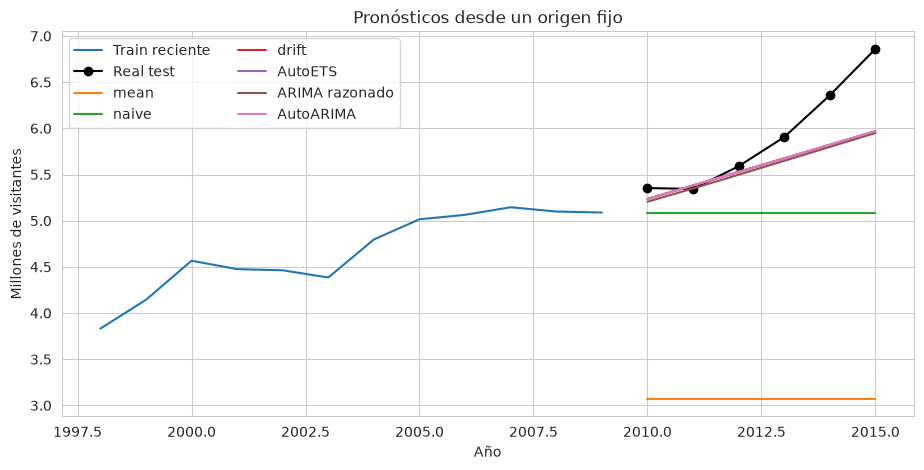

,anio,real,mean,naive,drift,AutoETS,ARIMA razonado,AutoARIMA
0,2010,5.353702,3.069473,5.088166,5.235003,5.234693,5.205025,5.235003
1,2011,5.343327,3.069473,5.088166,5.381840,5.381204,5.348616,5.381840
2,2012,5.589162,3.069473,5.088166,5.528677,5.527715,5.497784,5.528677
3,2013,5.904884,3.069473,5.088166,5.675514,5.674226,5.648116,5.675514
4,2014,6.357183,3.069473,5.088166,5.822351,5.820737,5.798690,5.822351
5,2015,6.858953,3.069473,5.088166,5.969188,5.967248,5.949315,5.969188


In [18]:
pronosticos={
 'mean':np.repeat(y_train.mean(),h), 'naive':np.repeat(y_train[-1],h),
 'drift':y_train[-1]+np.arange(1,h+1)*(y_train[-1]-y_train[0])/(len(y_train)-1),
 'AutoETS':ets.predict(h=h)['mean'],
 'ARIMA razonado':razonado.predict(h=h)['mean'], 'AutoARIMA':auto.predict(h=h)['mean']}
comparacion=pd.DataFrame({'anio':test.anio.to_numpy(),'real':y_test,**pronosticos})
fig,ax=plt.subplots(figsize=(11,5))
ax.plot(train.anio.tail(12),y_train[-12:],label='Train reciente')
ax.plot(test.anio,y_test,'ko-',label='Real test')
for nombre,pred in pronosticos.items():ax.plot(test.anio,pred,label=nombre)
ax.set(title='Pronósticos desde un origen fijo',xlabel='Año',ylabel='Millones de visitantes')
ax.legend(ncol=2)
plt.show()
display(comparacion)

## 10. MAE, RMSE y MASE
Para $e_t=y_t-\hat y_t$ en los mismos h años:
$$
MAE=\frac1h\sum|e_t|,\qquad RMSE=\sqrt{\frac1h\sum e_t^2}
$$
$$
MASE=\frac{MAE}{\frac1{T-1}\sum_{t=2}^{T}|y_t-y_{t-1}|}
$$
MAE/RMSE están en millones; RMSE penaliza errores grandes. MASE es adimensional y usa escala naive de un paso **solo de train**. Si es prácticamente cero, MASE no está definido. MASE<1 no demuestra vencer naive de varios pasos en test.

### 🧠 Predice → ▶ Ejecuta → 🔎 Interpreta
Anticipe el ranking y cuantifique la mejora o deterioro de ARIMA frente a drift y ETS.

In [19]:
def mae(real,pred):
    return float(np.mean(np.abs(np.asarray(real)-np.asarray(pred))))
def rmse(real,pred):
    return float(np.sqrt(np.mean((np.asarray(real)-np.asarray(pred))**2)))
def mase(historia,real,pred):
    escala=np.mean(np.abs(np.diff(np.asarray(historia))))
    return np.nan if np.isclose(escala,0) else mae(real,pred)/escala
metricas=pd.DataFrame([{'modelo':nombre,'MAE':mae(y_test,pred),'RMSE':rmse(y_test,pred),
                       'MASE':mase(y_train,y_test,pred)} for nombre,pred in pronosticos.items()]
                     ).set_index('modelo').sort_values('MAE')
display(metricas)
for nombre in ['ARIMA razonado','AutoARIMA']:
    base=metricas.loc['drift','MAE']
    print(nombre,'reducción MAE frente a drift (%):',100*(base-metricas.loc[nombre,'MAE'])/base if base>0 else np.nan)

,MAE,RMSE,MASE
modelo,,,
drift,0.311944,0.437716,1.694145
AutoARIMA,0.311944,0.437716,1.694145
AutoETS,0.312857,0.438841,1.699103
ARIMA razonado,0.328374,0.453830,1.783374
naive,0.813036,0.983169,4.415535
mean,2.831729,2.885184,15.378904


ARIMA razonado reducción MAE frente a drift (%): -5.266908094055425
AutoARIMA reducción MAE frente a drift (%): 0.0


<details>
<summary><strong>▶ Ver respuesta razonada</strong></summary>

Compare las filas calculadas: un empate AutoARIMA/drift surge de equivalencia estructural y no aporta mejora predictiva. MASE comparte denominador, así que su ranking coincide con MAE; RMSE puede cambiarlo. No decida entre ETS y ARIMA por AICc.

</details>

## 11. Diagnóstico residual
Residuos de un paso en train difieren de errores de varios pasos en test. Calculamos observado menos `predict_in_sample()['fitted']`, en unidades originales. Retiramos la primera observación de inicialización por d=1. Revisamos ambos ARIMA.

### 🧠 Predice
¿Una media residual próxima a cero prueba independencia?

### ▶ Ejecuta

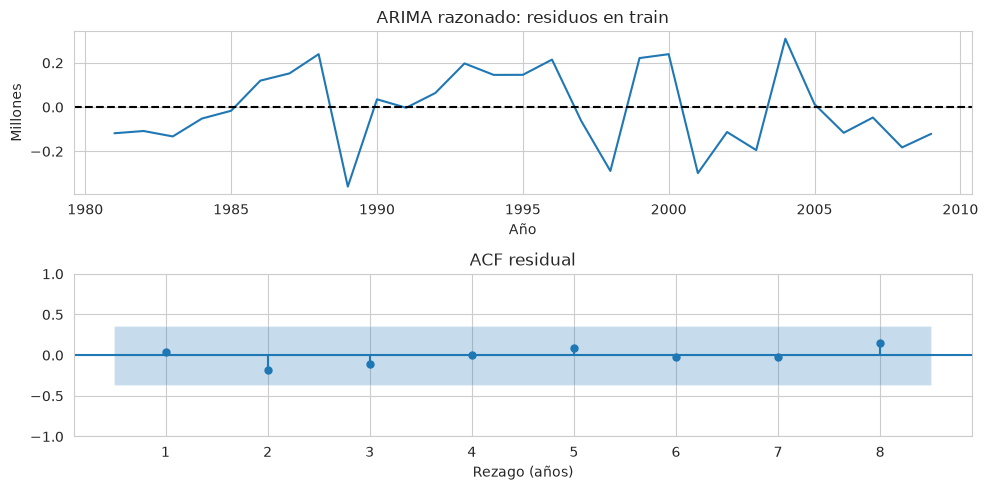

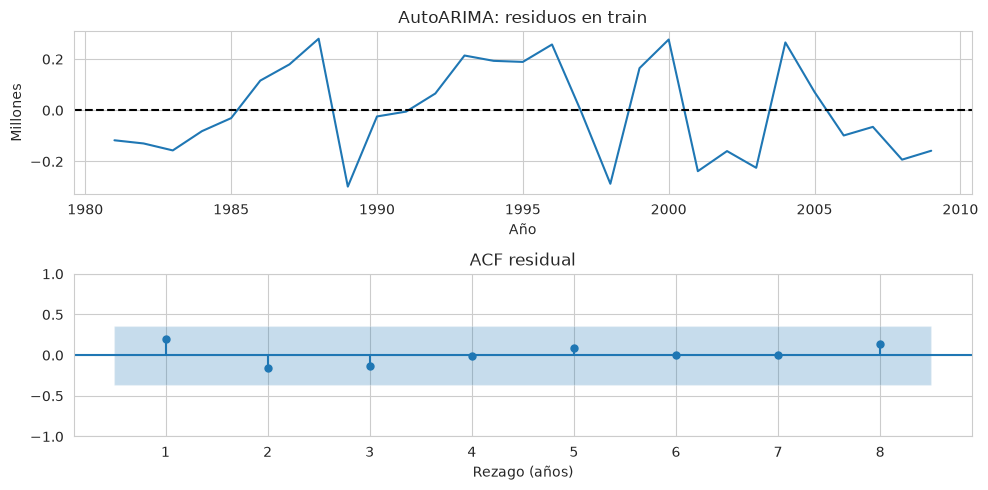

,media,sd,acf1
modelo,,,
ARIMA razonado,-4.081329e-03,0.178838,0.043781
AutoARIMA,-1.733479e-14,0.182819,0.203569


In [20]:
diagnosticos=[]
for nombre,modelo in [('ARIMA razonado',razonado),('AutoARIMA',auto)]:
    res=(y_train-modelo.predict_in_sample()['fitted'])[1:]
    assert np.isfinite(res).all()
    diagnosticos.append({'modelo':nombre,'media':res.mean(),'sd':res.std(ddof=1),'acf1':acf(res,nlags=1)[1]})
    fig,axes=plt.subplots(2,1,figsize=(10,5))
    axes[0].plot(train.anio.iloc[1:],res)
    axes[0].axhline(0,color='black',linestyle='--')
    axes[0].set(title=nombre+': residuos en train',xlabel='Año',ylabel='Millones')
    plot_acf(res,lags=8,zero=False,bartlett_confint=False,ax=axes[1])
    axes[1].set(title='ACF residual',xlabel='Rezago (años)')
    plt.tight_layout()
    plt.show()
display(pd.DataFrame(diagnosticos).set_index('modelo'))

### 🔎 Interpreta
Use media, escala, rachas y ACF completa. Distinga picos aislados y patrones sistemáticos.

<details>
<summary><strong>▶ Ver respuesta razonada</strong></summary>

Media pequeña no implica independencia. Las bandas son aproximadas y la muestra corta tiene poco poder; ausencia de picos no demuestra ruido blanco. Examine rachas y variabilidad. Buen diagnóstico tampoco garantiza menor error futuro.

</details>

### 🛠️ Modifica
Proponga otro orden pequeño sustentado en train y revise residuos. Declare el cambio antes de calcular métricas: tantear sobre test lo convierte en ajuste.

## 12. Decisión final provisional y puente al Hito 4
En 150–200 palabras elija benchmark, ETS o ARIMA. Cite MAE, RMSE, MASE, horizonte, orden seleccionado y evidencia residual. Cuantifique mejora o empate. Conservar drift es válido.

Un corte y seis errores anuales no sostienen conclusiones universales. Al comparar candidatos en este test, la conclusión es exploratoria; una confirmación requeriría nuevos datos o validación temporal adicional.

En **Hito 4** se recuperan benchmark de Hito 2 y mejor ETS/suavizamiento de Hito 3. Se agregan ARIMA razonado y AutoARIMA sobre la misma partición y se cierra el bloque con justificación, residuos y puente conceptual a estados Markov. No es obligatorio que gane ARIMA ni desarrollar SARIMA.

<details>
<summary><strong>▶ Ver respuesta razonada</strong></summary>

Para el corte 1980–2009 y horizonte 2010–2015 conservaría drift como decisión provisional. Drift y AutoARIMA empatan: MAE=0.312 millones, RMSE=0.438 y MASE=1.694. AutoETS queda muy cerca (0.313, 0.439, 1.699); ARIMA razonado obtiene (0.328, 0.454, 1.783), con MAE aproximadamente 5.27% mayor que drift. Estas diferencias pequeñas frente a ETS no justifican afirmar superioridad general.

AutoARIMA selecciona (0,1,0) con drift de 0.147 millones por año, equivalente a la referencia simple; no añade memoria AR/MA después de diferenciar. El AR(1) razonado reduce la ACF residual de lag 1 (aproximadamente 0.044 frente a 0.204), pero no mejora el pronóstico de este test. La media residual es pequeña en ambos casos; eso no prueba independencia. Conviene examinar todos los rezagos y las trayectorias residuales antes de cerrar el diagnóstico.

MASE supera 1 porque compara con la escala naive de un paso de train; aun así drift supera al naive de seis pasos en test. Seis errores y un único corte ofrecen evidencia limitada: la decisión debe revisarse con nuevos datos u orígenes temporales adicionales.

</details>